# 현실의 데이터 14: 뉴욕 택시 수요 예측 (시공간)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/14_taxi_demand.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 시공간 (spatiotemporal) 수요예측 · 모빌리티 · 배차 · 지도 데이터

> 뉴욕 택시 한 달 300만 번. 다음 한 시간, 어느 구역에서 택시를 몇 번 부를까?

**데이터**: NYC TLC Yellow Taxi Trip Records · 2024년 1월 (약 50MB). 뉴욕시 택시 · 리무진 위원회 (TLC) 공개 데이터: 노란 택시 승차 기록 약 296만 건 (승차 · 하차 시각, 구역 번호, 거리, 요금) + 택시 구역 263개 지도 (shapefile).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 구역 × 한 시간 |
| ② 입력 X | 그 구역의 지난 1 · 2시간, 어제 · 지난주 같은 시각 승차 수 + 이웃 구역 승차 수 + 시각 · 요일 |
| ③ 출력 y | 다음 한 시간 승차 수 |
| ④ 평가지표 | MAE (건) |
| ⑤ 기준선 | 지난 한 시간 그대로 · 지난주 같은 시각 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Yao et al. (2018) Deep Multi-View Spatial-Temporal Network for Taxi Demand Prediction, AAAI](https://arxiv.org/abs/1802.08714)
- [NYC TLC Trip Record Data (데이터 원본 · 설명)](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

승차 기록 (parquet, 약 50MB) + 택시 구역 지도 (shapefile).

In [2]:
BASE = "https://d37ci6vzurychx.cloudfront.net/"
trips = pd.read_parquet(download(BASE + "trip-data/yellow_tripdata_2024-01.parquet", "data/yellow_2024_01.parquet"),
                        columns=["tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", "total_amount"])
lookup = pd.read_csv(download(BASE + "misc/taxi_zone_lookup.csv", "data/taxi_zone_lookup.csv"))
print(trips.shape, trips["tpep_pickup_datetime"].min(), "~", trips["tpep_pickup_datetime"].max())
trips.sample(5, random_state=0)

(2964624, 5) 2002-12-31 22:59:39 ~ 2024-02-01 00:01:15


,tpep_pickup_datetime,PULocationID,DOLocationID,trip_distance,total_amount
839328,2024-01-11 00:58:21,230,79,2.96,20.60
458685,2024-01-06 13:37:33,68,246,1.10,16.80
2571791,2024-01-29 12:35:03,262,140,0.40,13.90
1988545,2024-01-23 13:40:35,211,33,2.80,19.60
1334002,2024-01-16 13:24:19,137,107,0.72,13.44


**관찰**: 2002년 · 2024년 2월 같은 날짜가 섞여 있다 (기계 시계 오류, 1주 3차시 '이상한 값'). 1월만 남긴다.

In [3]:
trips = trips[(trips["tpep_pickup_datetime"] >= "2024-01-01") & (trips["tpep_pickup_datetime"] < "2024-02-01")]
print(len(trips), "trips in January")
print(trips.merge(lookup, left_on="PULocationID", right_on="LocationID")["Zone"].value_counts().head(8))

2964606 trips in January
Zone
JFK Airport                     145240
Midtown Center                  143469
Upper East Side South           142707
Upper East Side North           136464
Midtown East                    106717
Times Sq/Theatre District       106324
Penn Station/Madison Sq West    104522
Lincoln Square East             104080
Name: count, dtype: int64


## 지도 파일 열어 보기

shapefile 도 결국 숫자 묶음이다 (`.shp` = 구역마다 꼭짓점 좌표, `.dbf` = 구역 이름 표). 라이브러리 없이 직접 읽어 보자.

263 polygons; [{'LocationID': 1, 'zone': 'Newark Airport', 'borough': 'EWR'}, {'LocationID': 2, 'zone': 'Jamaica Bay', 'borough': 'Queens'}, {'LocationID': 3, 'zone': 'Allerton/Pelham Gardens', 'borough': 'Bronx'}]


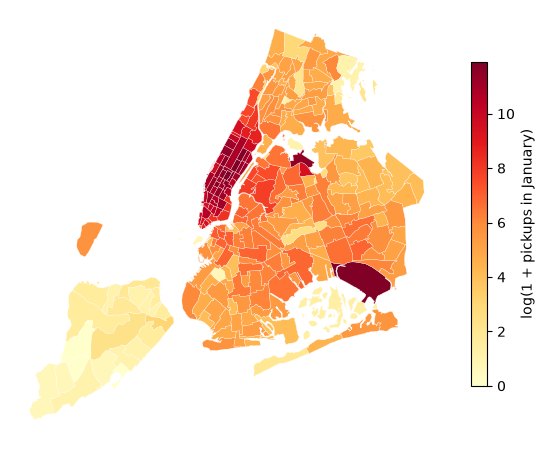

In [4]:
import struct
from matplotlib.collections import PolyCollection

def read_shp(b):
    """Polygons of a .shp file: list (one per record) of point arrays (one per part)"""
    shapes, pos = [], 100
    while pos < len(b):
        _, length = struct.unpack(">ii", b[pos:pos + 8]); rec = b[pos + 8:pos + 8 + length * 2]; pos += 8 + length * 2
        if struct.unpack("<i", rec[:4])[0] == 0:
            shapes.append([]); continue
        nparts, npts = struct.unpack("<ii", rec[36:44])
        parts = list(struct.unpack(f"<{nparts}i", rec[44:44 + 4 * nparts])) + [npts]
        pts = np.frombuffer(rec[44 + 4 * nparts:44 + 4 * nparts + 16 * npts], dtype="<f8").reshape(-1, 2)
        shapes.append([pts[parts[i]:parts[i + 1]] for i in range(nparts)])
    return shapes

def read_dbf(b):
    """Attribute table of a .dbf file as a DataFrame"""
    nrec, hlen, rlen = struct.unpack("<IHH", b[4:12]); fields, p = [], 32
    while b[p] != 0x0D:
        fields.append((b[p:p + 11].split(b"\0")[0].decode(), b[p + 16])); p += 32
    rows = []
    for r in range(nrec):
        rec, o, row = b[hlen + r * rlen + 1:hlen + (r + 1) * rlen], 0, {}
        for name, flen in fields:
            row[name] = rec[o:o + flen].decode("latin1").strip(); o += flen
        rows.append(row)
    return pd.DataFrame(rows)

with zipfile.ZipFile(download(BASE + "misc/taxi_zones.zip", "data/taxi_zones.zip")) as z:
    shapes = read_shp(z.read("taxi_zones/taxi_zones.shp")); zones = read_dbf(z.read("taxi_zones/taxi_zones.dbf"))
zones["LocationID"] = zones["LocationID"].astype(int)
print(len(shapes), "polygons;", zones[["LocationID", "zone", "borough"]].head(3).to_dict("records"))

def draw_zones(ax, values, shapes, zones, cmap="YlOrRd"):
    """Colour each taxi zone by values[LocationID]"""
    polys, vals = [], []
    for s, zid in zip(shapes, zones["LocationID"]):
        for part in s:
            polys.append(part); vals.append(values.get(zid, 0))
    pc = PolyCollection(polys, array=np.log1p(np.array(vals, dtype=float)), cmap=cmap, edgecolor="white", linewidth=0.2)
    ax.add_collection(pc); ax.autoscale(); ax.set_aspect("equal"); ax.axis("off")
    return pc

fig, ax = plt.subplots(figsize=(7, 7))
pc = draw_zones(ax, trips["PULocationID"].value_counts().to_dict(), shapes, zones)
plt.colorbar(pc, ax=ax, shrink=0.6, label="log(1 + pickups in January)"); plt.show()

## 시공간 표로 바꾸기: 시간 × 구역

한 행 = (시간, 구역). 744시간 × 263구역. 맨해튼 한가운데와 공항 (JFK · 라과디아) 이 가장 많다.

(744, 263)


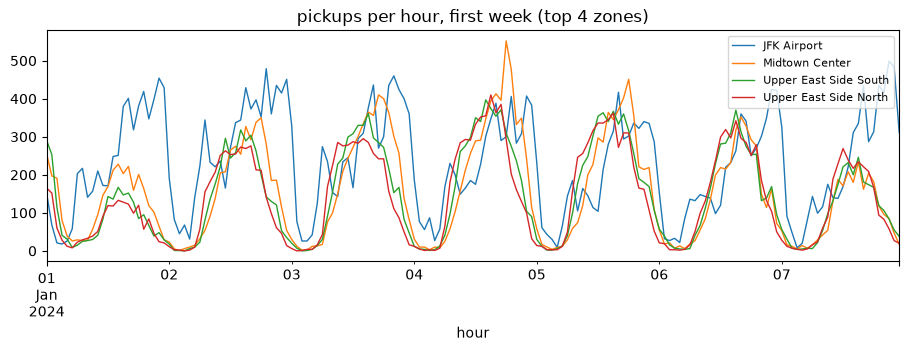

In [5]:
trips["hour"] = trips["tpep_pickup_datetime"].dt.floor("h")
counts = trips.groupby(["hour", "PULocationID"]).size().unstack(fill_value=0).reindex(columns=range(1, 264), fill_value=0)
print(counts.shape)
top = counts.sum().sort_values(ascending=False).head(4).index
counts[top].iloc[:24 * 7].plot(figsize=(11, 3), lw=1, title="pickups per hour, first week (top 4 zones)")
plt.legend([lookup.set_index("LocationID").loc[z, "Zone"] for z in top], fontsize=8); plt.show()

## 문제 하나 골라 보기: (구역, 시간) → 다음 한 시간 승차 수

**시간 순서**: 1월 25일 전 학습, 그 뒤 시험. 입력에 **이웃 구역** (지도에서 가까운 5개) 의 지난 한 시간 승차 수를 넣는다 = 공간 정보.
기준선: 지난 한 시간 그대로, 지난주 같은 시각.

In [6]:
from scipy.spatial import cKDTree
from sklearn.ensemble import HistGradientBoostingRegressor

centre = pd.DataFrame([np.concatenate(s).mean(0) if s else [np.nan, np.nan] for s in shapes], columns=["x", "y"])
centre["LocationID"] = zones["LocationID"].values
centre = centre.groupby("LocationID").mean().dropna()
_, nb = cKDTree(centre.values).query(centre.values, k=6)
neighbours = {z: [centre.index[j] for j in row[1:]] for z, row in zip(centre.index, nb)}

def make_rows(counts, neighbours):
    """(hour, zone) rows with past counts of the zone and of its neighbours"""
    f = pd.DataFrame({f"lag{k}": counts.shift(k).stack() for k in (1, 2, 24, 168)})
    f["neigh1"] = pd.DataFrame({z: counts[neighbours[z]].sum(1) if z in neighbours else 0 for z in counts.columns}).shift(1).stack()
    f["y"] = counts.stack()
    f = f.dropna().reset_index(); f.columns = ["hour", "zone"] + list(f.columns[2:])
    f["hod"], f["dow"] = f["hour"].dt.hour, f["hour"].dt.dayofweek
    return f

rows = make_rows(counts, neighbours)
tr, te = rows[rows["hour"] < "2024-01-25"].copy(), rows[rows["hour"] >= "2024-01-25"].copy()
zone_mean = tr.groupby("zone")["y"].mean(); tr["zmean"] = tr["zone"].map(zone_mean); te["zmean"] = te["zone"].map(zone_mean)
feats = ["lag1", "lag2", "lag24", "lag168", "neigh1", "hod", "dow", "zmean"]
m = HistGradientBoostingRegressor(random_state=0, max_iter=300).fit(tr[feats], tr["y"])
print(f"test rows {len(te):,}, mean pickups per zone-hour {te['y'].mean():.1f}")
for name, pred in [("last hour", te["lag1"]), ("same hour last week", te["lag168"]), ("gradient boosting", m.predict(te[feats]))]:
    print(f"{name:20s} MAE {np.mean(np.abs(pred - te['y'])):.2f} pickups")

/var/folders/v4/bx21yqsx7h5gjv30q9pfm2t00000gn/T/ipykernel_16103/1923298327.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  f["neigh1"] = pd.DataFrame({z: counts[neighbours[z]].sum(1) if z in neighbours else 0 for z in counts.columns}).shift(1).stack()
/var/folders/v4/bx21yqsx7h5gjv30q9pfm2t00000gn/T/ipykernel_16103/1923298327.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  f["neigh1"] = pd.DataFrame({z: counts[neighbours[z]].sum(1) if z in neighbours else 0 for z in counts.columns}).shift(1).stack()
/var/folders/v4/bx21yqsx7h5gjv30q9pfm2t00000gn/T/ipykernel_16103/1923298327.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  f["neigh1"] = pd.DataFrame({z: counts[neighbours[z]].sum(1) if z in neighbours else 0 for z in counts.columns}).shift(1).stack()
/var/folders/v4/bx21yqsx7h5gjv30q9pfm2t00000gn/T/ipykernel_16103/1923298327.py:13:

test rows 44,184, mean pickups per zone-hour 15.9
last hour            MAE 4.35 pickups
same hour last week  MAE 2.98 pickups
gradient boosting    MAE 2.69 pickups


**관찰**: '지난 한 시간 그대로' 보다 '지난주 같은 시각' 이 낫다 (출퇴근 · 요일 패턴). 모델은 둘을 섞고 이웃 구역까지 봐서 더 낫다. 실제 배차 회사는 날씨 · 행사 (경기 · 공연) 까지 입력에 넣는다.

## 다른 문제로 바꿔 보기

- **배차 · 요금**: '수요' 만이 아니라 '공급 (빈 택시)' 도 구역 × 시간으로 맞히면, 어디로 택시를 보낼지 · 할증을 얼마나 붙일지 정할 수 있다.
- **도착 시간 (ETA)**: 한 행 = 운행 한 번, 입력 = 출발 · 도착 구역 · 시각, 출력 = 걸린 분 (`tpep_dropoff_datetime − tpep_pickup_datetime`).
- **그래프로**: 구역을 점, 이웃을 선으로 두면 13주차 그래프 신경망 문제가 된다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |